In [1]:
import torch 
import torch.nn as nn
from torch import cat
import matplotlib.pyplot as plt
import torch.nn.functional as F
import gymnasium as gym
from tqdm import tqdm
import numpy as np
import collections
#from collections import deque
import random
import os

os.environ['KMP_DUPLICATE_LIB_OK']='True'

In [2]:
class ReplayBuffer:
    def __init__(self, capacity):
        self.buffer = collections.deque(maxlen=capacity) 

    def add(self, state, action, reward, next_state, done): 
        self.buffer.append((state, action, reward, next_state, done)) 

    def sample(self, batch_size): 
        transitions = random.sample(self.buffer, batch_size)
        state, action, reward, next_state, done = zip(*transitions)
        return np.array(state), action, reward, np.array(next_state), done 

    def size(self): 
        return len(self.buffer)

class OrnsteinUhlenbeckNoise:
    def __init__(self, mu, sigma=0.15, theta=0.2, dt=1e-2, x0=None):
        self.mu = mu
        self.sigma = sigma
        self.theta = theta
        self.dt = dt
        self.x0 = x0
        self.reset()

    def reset(self):
        self.x_prev = self.x0 if self.x0 is not None else np.zeros_like(self.mu)
    
    def noise(self):
        x = self.x_prev + self.theta*(self.mu - self.x_prev) * self.dt + self.sigma*np.sqrt(self.dt)*np.random.normal(size=self.mu.shape)
        self.x_prev = x
        return x

In [3]:
class PolicyNet(nn.Module):
    def __init__(self, state_dim, action_dim, hidden_dim1, hidden_dim2):
        super(PolicyNet, self).__init__()
        self.fc1 = nn.Linear(state_dim, hidden_dim1)
        f1 = 1/np.sqrt(self.fc1.weight.data.size()[0])
        nn.init.uniform_(self.fc1.weight, -f1, f1)
        nn.init.uniform_(self.fc1.bias, -f1, f1)
        self.bn1 = nn.LayerNorm(hidden_dim1)

        self.fc2 = nn.Linear(hidden_dim1, hidden_dim2)
        f2 = 1/np.sqrt(self.fc2.weight.data.size()[0])
        nn.init.uniform_(self.fc2.weight, -f2, f2)
        nn.init.uniform_(self.fc2.bias, -f2, f2)
        self.bn2 = nn.LayerNorm(hidden_dim2)

        f3=0.0003
        self.mu = nn.Linear(hidden_dim2, action_dim)
        nn.init.uniform_(self.mu.weight, -f3, f3)
        nn.init.uniform_(self.mu.bias, -f3*0.1, f3*0.1)

    def forward(self, state):
        x = self.fc1(state)
        x = self.bn1(x)
        x = F.relu(x)

        x = self.fc2(x)
        x = self.bn2(x)
        x = F.relu(x)
        return torch.tanh(self.mu(x))

class QValueNet(nn.Module):
    def __init__(self, state_dim, action_dim, hidden_dim1, hidden_dim2):
        super(QValueNet, self).__init__()
        
        self.fc1 = nn.Linear(state_dim, hidden_dim1)
        f1 = 1/np.sqrt(self.fc1.weight.data.size()[0])
        nn.init.uniform_(self.fc1.weight, -f1, f1)
        nn.init.uniform_(self.fc1.bias, -f1, f1)
        self.bn1 = nn.LayerNorm(hidden_dim1)

        self.fc2 = nn.Linear(hidden_dim1 + action_dim, hidden_dim2)
        f2 = 1/np.sqrt(self.fc2.weight.data.size()[0])
        nn.init.uniform_(self.fc2.weight, -f2, f2)
        nn.init.uniform_(self.fc2.bias, -f2, f2)
        self.bn2 = nn.LayerNorm(hidden_dim2)

        self.q = nn.Linear(hidden_dim2, 1)
        f3=0.0003
        nn.init.uniform_(self.q.weight, -f3, f3)
        nn.init.uniform_(self.q.bias, -f3*0.1, f3*0.1)

    def forward(self, state, action):
        x = self.fc1(state)
        x = self.bn1(x)
        x = F.relu(x)

        x = torch.cat([x, action], 1)
        x = self.fc2(x)
        x = self.bn2(x)
        x = F.relu(x)

        V = self.q(x)
        return V

In [11]:
class DDPG:
    ''' DDPG '''
    def __init__(self, state_dim, hidden_dim1, hidden_dim2, action_dim, actor_lr, critic_lr, tau, gamma, device):
        self.actor = PolicyNet(state_dim, action_dim, hidden_dim1, hidden_dim2).to(device)
        self.critic = QValueNet(state_dim, action_dim, hidden_dim1, hidden_dim2).to(device)
        self.target_actor = PolicyNet(state_dim, action_dim, hidden_dim1, hidden_dim2).to(device)
        self.target_critic = QValueNet(state_dim, action_dim, hidden_dim1, hidden_dim2).to(device)
        self.actor_optimizer = torch.optim.AdamW(self.actor.parameters(), lr = actor_lr)
        self.critic_optimizer = torch.optim.AdamW(self.critic.parameters(), lr = critic_lr, weight_decay=1e-2)       
        self.gamma = gamma
        self.tau = tau
        self.action_dim = action_dim
        self.device = device

        self.hard_update(self.target_actor, self.actor)
        self.hard_update(self.target_critic, self.critic)

    def take_action(self, state, action_noise):
        self.actor.eval()
        state = torch.tensor(state).unsqueeze(0).float().to(self.device)
        mu = self.actor(state)
        self.actor.train()
        mu = mu.data

        if action_noise is not None:
            noise = torch.tensor(action_noise.noise()).to(self.device)
            mu += noise    
        return mu
        
    def soft_update(self, net, target_net):
        for param_target, param in zip(target_net.parameters(), net.parameters()):
            param_target.data.copy_(param_target.data * (1.0 - self.tau) + param.data * self.tau)

    def hard_update(self, net, target_net):
        for param_target, param in zip(target_net.parameters(), net.parameters()):
            param_target.data.copy_(param.data)
    
    def update(self, transition_dict):
        states = torch.tensor(transition_dict['states'], dtype=torch.float).to(self.device)
        actions = torch.tensor(transition_dict['actions'], dtype=torch.float).to(self.device)
        rewards = torch.tensor(transition_dict['rewards'], dtype=torch.float).view(-1, 1).to(self.device)
        next_states = torch.tensor(transition_dict['next_states'], dtype=torch.float).to(self.device)
        dones = torch.tensor(transition_dict['dones'], dtype=torch.float).view(-1, 1).to(self.device)

        next_q_values = self.target_critic(next_states, self.target_actor(next_states).detach())
        q_targets = rewards + self.gamma * next_q_values * (1 - dones)
        critic_loss = F.mse_loss(self.critic(states, actions), q_targets.detach())
        self.critic_optimizer.zero_grad()
        critic_loss.backward()
        self.critic_optimizer.step()

        actor_loss = -torch.mean(self.critic(states, self.actor(states)))
        self.actor_optimizer.zero_grad()
        actor_loss.backward()
        self.actor_optimizer.step()

        self.soft_update(self.actor, self.target_actor)  # Actualizacion suave para el actor
        self.soft_update(self.critic, self.target_critic)  # Actualizacion suave para el critico
        return critic_loss.item(), actor_loss.item()

In [12]:
actor_lr = 1e-4 
critic_lr = 1e-3
num_episodes = 400
hidden_dim1 = 400
hidden_dim2 = 300
gamma = 0.99
tau = 0.05
buffer_size = 1_000_000
batch_size=128
minimal_size = 128
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

env_name = 'Ant-v5'
env = gym.make(env_name)
random.seed(0)
np.random.seed(0)
torch.manual_seed(0)
replay_buffer = ReplayBuffer(buffer_size)
state_dim = env.observation_space.shape[0]
action_dim = env.action_space.shape[0]
ou_noise = OrnsteinUhlenbeckNoise(mu=np.zeros(action_dim))
agent = DDPG(state_dim, hidden_dim1, hidden_dim2, action_dim, actor_lr, critic_lr, tau, gamma, device)

return_list = []
for i in range(10):
    with tqdm(total=int(num_episodes/10), desc='Iteracion %d' % i) as pbar:
        for i_episode in range(int(num_episodes/10)):
            episode_return = 0
            state, _ = env.reset(seed = 0)
            timesteps = 0
            done = False
            while not done:
                timesteps += 1
                action = agent.take_action(state, ou_noise).cpu().numpy()[0]
                next_state, reward, done, truncated, _ = env.step(action)
                replay_buffer.add(state, action, reward, next_state, done)
                state = next_state
                episode_return += reward

                epoch_critic_loss = 0
                epoch_actor_loss = 0
                if replay_buffer.size() > minimal_size:
                    b_s, b_a, b_r, b_ns, b_d = replay_buffer.sample(batch_size)
                    transition_dict = {'states': b_s, 'actions': b_a, 'next_states': b_ns, 'rewards': b_r, 'dones': b_d}
                    critic_loss, actor_loss = agent.update(transition_dict)
                    epoch_critic_loss += critic_loss
                    epoch_actor_loss += actor_loss
                if truncated:
                    #print(f"Episodio Truncado en {timesteps}")
                    break
            return_list.append(episode_return)
            if (i_episode+1) % 10 == 0:
                pbar.set_postfix({'Episodio': '%d' % (num_episodes/10 * i + i_episode+1),
                                  'Retorno': '%.3f' % np.mean(return_list[-10:]),
                                  'Critic loss': '%.3f' % epoch_critic_loss,
                                  'Actor loss': '%.3f' % epoch_actor_loss})
            pbar.update(1)
            if (i_episode + 1) % 40 == 0:
                torch.save(agent.actor.state_dict(), f"models\ddpg_ant_{10*i + i_episode + 1}.pt")
                print(f"...... Modelo del episodio {10*i + i_episode + 1} guardado ......")

Iteracion 0: 100%|█| 40/40 [02:52<00:00,  4.32s/it, Episodio=40, Retorno=-494.008, Critic loss=8.244, Actor loss=-75.76


...... Modelo del episodio 40 guardado ......


Iteracion 1: 100%|█| 40/40 [03:48<00:00,  5.72s/it, Episodio=80, Retorno=-127.143, Critic loss=5.880, Actor loss=-61.14


...... Modelo del episodio 50 guardado ......


Iteracion 2: 100%|█| 40/40 [04:51<00:00,  7.30s/it, Episodio=120, Retorno=152.017, Critic loss=9.198, Actor loss=-86.30


...

...... Modelo del episodio 110 guardado ......


Iteracion 8: 100%|█| 40/40 [03:57<00:00,  5.93s/it, Episodio=360, Retorno=-325.070, Critic loss=8.681, Actor loss=-98.9


...... Modelo del episodio 120 guardado ......


Iteracion 9: 100%|█| 40/40 [03:34<00:00,  5.36s/it, Episodio=400, Retorno=127.115, Critic loss=8.059, Actor loss=-109.5

...... Modelo del episodio 130 guardado ......


In [15]:
def moving_average(a, window_size):
    cumulative_sum = np.cumsum(np.insert(a, 0, 0)) 
    middle = (cumulative_sum[window_size:] - cumulative_sum[:-window_size]) / window_size
    r = np.arange(1, window_size-1, 2)
    begin = np.cumsum(a[:window_size-1])[::2] / r
    end = (np.cumsum(a[:-window_size:-1])[::2] / r)[::-1]
    return np.concatenate((begin, middle, end))

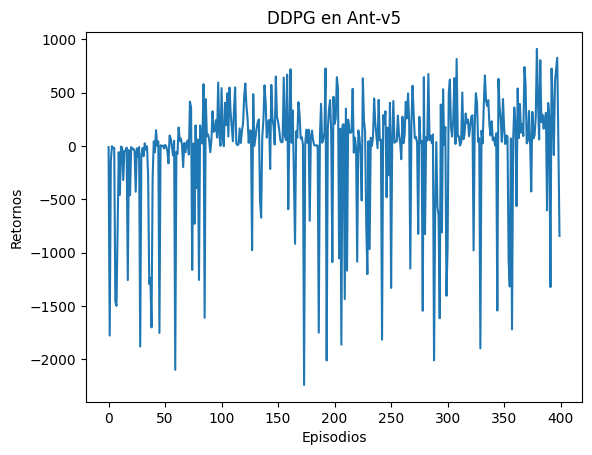

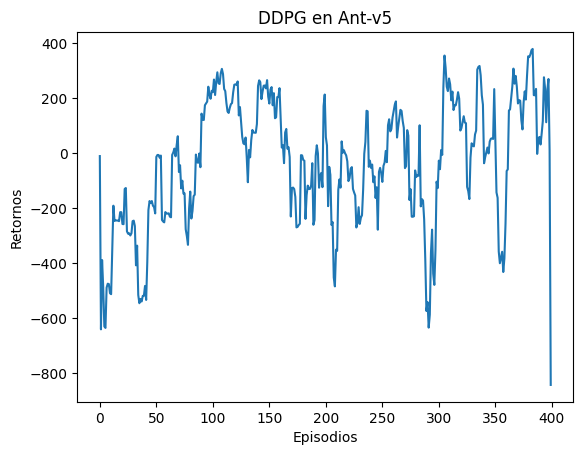

In [16]:
episodes_list = list(range(len(return_list)))
plt.plot(episodes_list, return_list)
plt.xlabel('Episodios')
plt.ylabel('Retornos')
plt.title('DDPG en {}'.format(env_name))
plt.show()

mv_return = moving_average(return_list, 9)
plt.plot(episodes_list, mv_return)
plt.xlabel('Episodios')
plt.ylabel('Retornos')
plt.title('DDPG en {}'.format(env_name))
plt.show()

In [14]:
from gymnasium.wrappers import RecordVideo

env = gym.make("Ant-v5", render_mode="human")
#env = RecordVideo(env, video_folder='videos/0_episodes', episode_trigger=lambda x: x%1==0)
state_dims, action_dims = env.observation_space.shape[0], env.action_space.shape[0]

actor = PolicyNet(state_dims, action_dims, 400, 300)
actor.load_state_dict(torch.load("models\ddpg_ant_130.pt", weights_only = True))

for episode in range(10):
    state, _ = env.reset()
    state = torch.tensor(state).unsqueeze(0).float()
    done=False
    while not done:
        action = actor(state)
        next_state, reward, done, trunc, info = env.step(action.detach().numpy().reshape(action_dims))
        next_state = torch.tensor(next_state).unsqueeze(0).float()
        state=next_state
        if trunc:
            break
env.close()

